# Differential geometry 3: Surfaces

*Learning path: differential geometry, part 3 of 7.* [Index](README.md) · Previous: [Metrics](02-metrics.ipynb) · Next: [Gaussian curvature](04-gaussian-curvature.ipynb)

A surface in space, like a sphere or a doughnut, is described by two parameters $(u, v)$ and a map to a point
$\big(x(u,v), y(u,v), z(u,v)\big)$. An ant living on the surface knows nothing about the space around it; all it can
measure is distances along the surface. Those are given by the **induced metric**, also called the *first
fundamental form*. You will learn

* how to describe surfaces with parameters, and draw them in 3D,
* how the induced metric follows from the map,
* how to compute areas from the metric,
* that very different-looking surfaces can have the same metric.

In JupyterLab the 3D pictures are interactive: drag to rotate, scroll to zoom.

## 1. How the induced metric works

Moving $du$ and $dv$ on the surface moves the point in space by $d\vec X = \vec X_u\,du + \vec X_v\,dv$. Its length
squared is

$$ds^2 = (\vec X_u\cdot\vec X_u)\,du^2 + 2(\vec X_u\cdot\vec X_v)\,du\,dv + (\vec X_v\cdot\vec X_v)\,dv^2$$

so $g_{ab} = \vec X_a \cdot \vec X_b$. That is what `inducedmetric(map, [u v])` computes.

## 2. The sphere

In [1]:
sphere = [r*sin(theta)*cos(phi) r*sin(theta)*sin(phi) r*cos(theta)];
inducedmetric(sphere, [theta phi])

$$ds^2 = r^{2}\, d\theta^2 + r^{2} \sin^{2}\left(\theta\right)\, d\phi^2$$

Moving along a meridian ($d\theta$) always counts $r\,d\theta$, but moving along a circle of latitude ($d\phi$) counts
only $r\sin\theta\,d\phi$, because those circles shrink towards the poles.

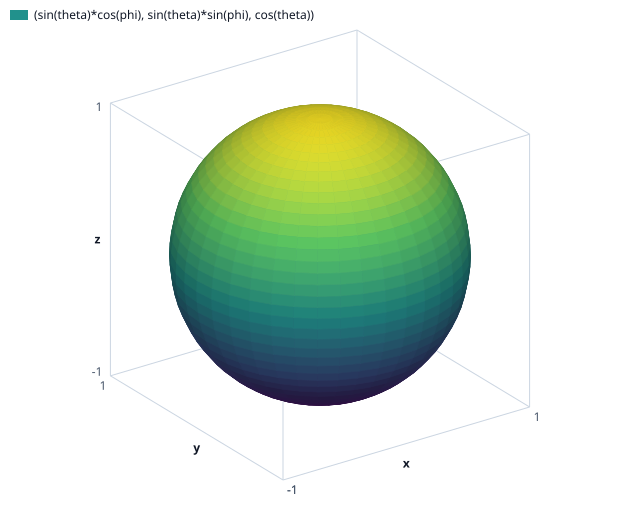

In [2]:
r = 1;
surface(sin(theta)*cos(phi), sin(theta)*sin(phi), cos(theta), theta, 0, pi, phi, 0, 2*pi)

## 3. Cylinder and cone

A cylinder of radius 1, with height $h$ and angle $v$:

In [3]:
clear
cylinder = [cos(v) sin(v) h];
inducedmetric(cylinder, [h v])

$$ds^2 = \, dh^2 + \, dv^2$$

$ds^2 = dh^2 + dv^2$: exactly the metric of a flat sheet of paper. That makes sense, since you can roll a sheet of
paper into a cylinder without stretching it. The ant on the cylinder cannot tell it from a plane, at least not
locally.

A cone with opening angle 45°, with $w$ the distance from the axis:

In [4]:
cone = [w*cos(v) w*sin(v) w];
inducedmetric(cone, [w v])

$$ds^2 = 2\, dw^2 + w^{2}\, dv^2$$

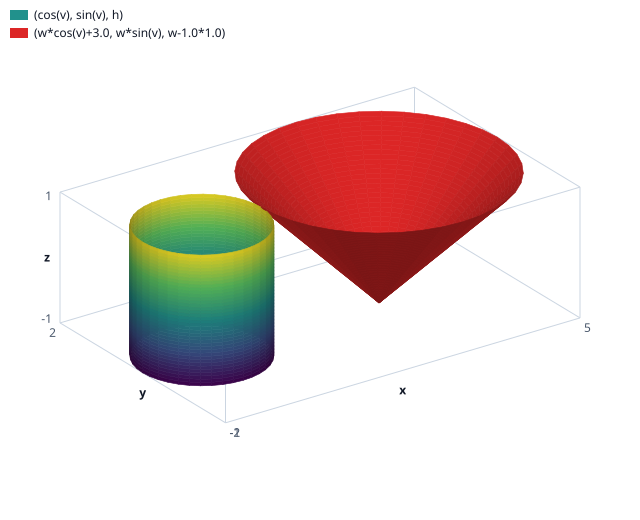

In [5]:
show(surface(cos(v), sin(v), h, h, -1, 1, v, 0, 2*pi), surface(w*cos(v) + 3, w*sin(v), w - 1, w, 0, 2, v, 0, 2*pi))

The cone, too, can be made from paper: a disc with a wedge cut out. With $\rho = \sqrt2\,w$ (distance measured along
the cone) and $\alpha = v/\sqrt2$ the metric becomes $d\rho^2 + \rho^2\,d\alpha^2$, the flat plane in polar
coordinates, but $\alpha$ only runs to $2\pi/\sqrt2$.

## 4. The torus

A doughnut: a tube of radius $a$ swept around a circle of radius $R$.

In [6]:
clear
torus = [(R+a*cos(u))*cos(v) (R+a*cos(u))*sin(v) a*sin(u)];
t = inducedmetric(torus, [u v])

$$ds^2 = a^{2}\, du^2 + \left(R + a \cos\left(u\right)\right)^{2}\, dv^2$$

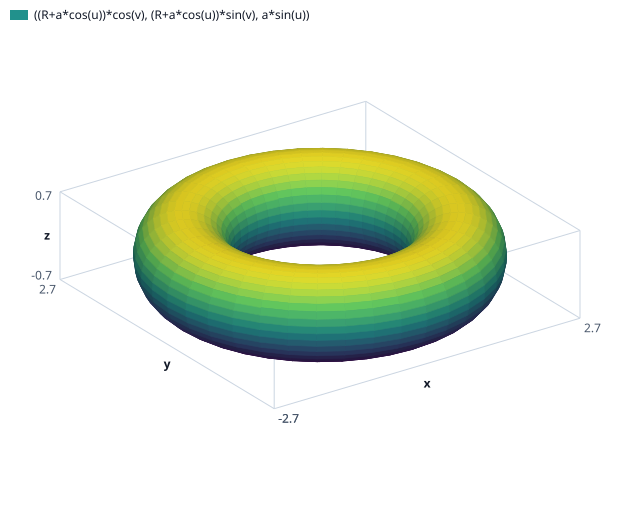

In [7]:
R = 2;
a = 0.7;
surface((R+a*cos(u))*cos(v), (R+a*cos(u))*sin(v), a*sin(u), u, 0, 2*pi, v, 0, 2*pi)

Going around the hole ($dv$) is longer on the outside ($u = 0$, factor $R + a$) than on the inside ($u = \pi$, factor
$R - a$). That difference is why a torus, unlike a cylinder, cannot be made from flat paper.

## 5. Graphs and saddles

Any function $z = f(x, y)$ defines a surface. The paraboloid $z = u^2 + v^2$ and the saddle $z = u^2 - v^2$:

In [8]:
clear
inducedmetric([u v u^2+v^2], [u v])
inducedmetric([u v u^2-v^2], [u v])

$$ds^2 = \left(4 u^{2} + 1\right)\, du^2 + 8 u v\, du\, dv + \left(4 v^{2} + 1\right)\, dv^2$$

$$ds^2 = \left(4 u^{2} + 1\right)\, du^2 - 8 u v\, du\, dv + \left(4 v^{2} + 1\right)\, dv^2$$

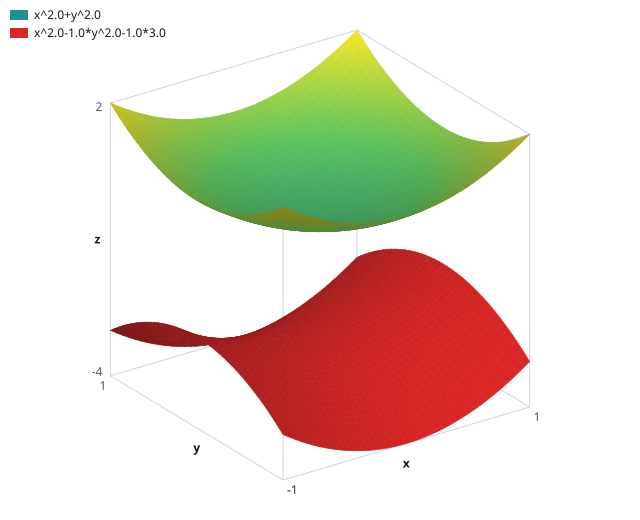

In [9]:
show(plot3d(x^2+y^2, x, -1, 1, y, -1, 1), plot3d(x^2-y^2 - 3, x, -1, 1, y, -1, 1))

Now an off-diagonal term $du\,dv$ appears: the coordinate lines are no longer perpendicular on the surface.

## 6. Area

The area of a small patch $du\,dv$ is $\sqrt{\det g}\;du\,dv$. For the sphere, $\det g = r^4\sin^2\theta$, so the area
element is $r^2\sin\theta\,d\theta\,d\phi$. Integrating $\phi$ gives $2\pi$; the $\theta$ integral we do numerically,
for $r = 1$:

In [10]:
A = odesolve([2*pi*sin(theta)], [area], theta, [0], 0, pi)
eval(4*pi)

12.566370614361887
12.566370614359172

For the torus, $\det g = a^2 (R + a\cos u)^2$, and the area is $4\pi^2 R a$ (Pappus's theorem):

In [11]:
R = 2;
a = 0.7;
odesolve([2*pi*a*(R + a*cos(u))], [area], u, [0], 0, 2*pi)
eval(4*pi^2*R*a)

55.269784646097825
55.269784646100405

## 7. Same metric, different shape: the helicoid

The helicoid is the shape of a spiral staircase, or of a soap film on a helical wire:

In [12]:
clear
helicoid = [w*cos(v) w*sin(v) v];
inducedmetric(helicoid, [w v])

$$ds^2 = \, dw^2 + \left(w^{2} + 1\right)\, dv^2$$

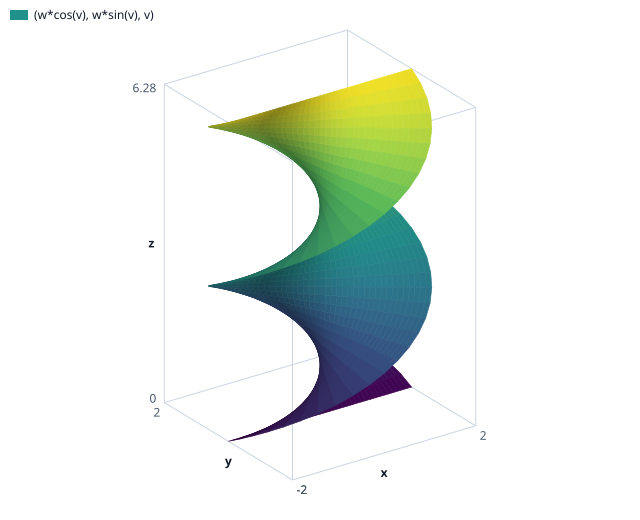

In [13]:
surface(w*cos(v), w*sin(v), v, w, -2, 2, v, 0, 2*pi)

Its metric $dw^2 + (1 + w^2)\,dv^2$ is also the metric of the *catenoid*, the soap film between two rings, written
in suitable coordinates. A helicoid made of a flexible, unstretchable film can be bent into a catenoid. Same metric
means the ant cannot tell the two apart, even though they look completely different from outside. Part 4 makes that
precise.

## Summary

* A surface is a map from parameters $(u, v)$ into space; `surface(...)` draws it.
* The induced metric $g_{ab} = \vec X_a \cdot \vec X_b$ is all an inhabitant can measure.
* Areas follow from $\sqrt{\det g}$.
* Cylinders and cones have the metric of a flat plane; spheres and tori do not.

**Try it:** the *Enneper surface* `[u-u^3/3+u*v^2, v-v^3/3+v*u^2, u^2-v^2]` is a famous soap film. Compute its induced
metric and draw it for $u, v$ between $-2$ and $2$.

Next: [Gaussian curvature](04-gaussian-curvature.ipynb), the number that tells the ant whether it lives on a curved
surface.